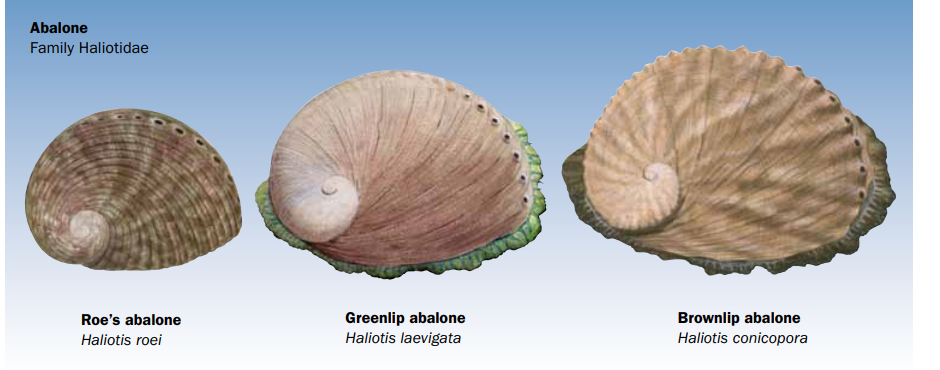

# Libraries

In [1]:
import numpy as np # Linear algebra
import pandas as pd # data processing

#Visualisations Libraries
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
import warnings
warnings.filterwarnings('ignore')

# Upload data 

In [2]:
data = pd.read_csv("abalone.csv")
#creating age column
data['Age'] = data.Rings+1.5
data.drop("Rings",axis = 1, inplace= True)
data.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Age
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,16.5
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,8.5
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,10.5
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,11.5
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,8.5


In [3]:
data.describe()

,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Age
count,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000
mean,0.523992,0.407881,0.139516,0.828742,0.359367,0.180594,0.238831,11.433684
std,0.120093,0.099240,0.041827,0.490389,0.221963,0.109614,0.139203,3.224169
min,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,2.500000
25%,0.450000,0.350000,0.115000,0.441500,0.186000,0.093500,0.130000,9.500000
50%,0.545000,0.425000,0.140000,0.799500,0.336000,0.171000,0.234000,10.500000
75%,0.615000,0.480000,0.165000,1.153000,0.502000,0.253000,0.329000,12.500000
max,0.815000,0.650000,1.130000,2.825500,1.488000,0.760000,1.005000,30.500000


# Exploratory Data Analysis
Understanding our data

In [4]:
#Data Shape below shows that our data have 9 columns and 4177 records.
data.shape

(4177, 9)

### Missing value
We need to confirm if our data doesn't have missing values using a heatmap plot so that we can work with a unique dataset. If there is a column with missing values, that column or feature will show dashes on the heatmap plot. Below the heat map is blank which means we have no missing values in our housing data. 

<AxesSubplot:>

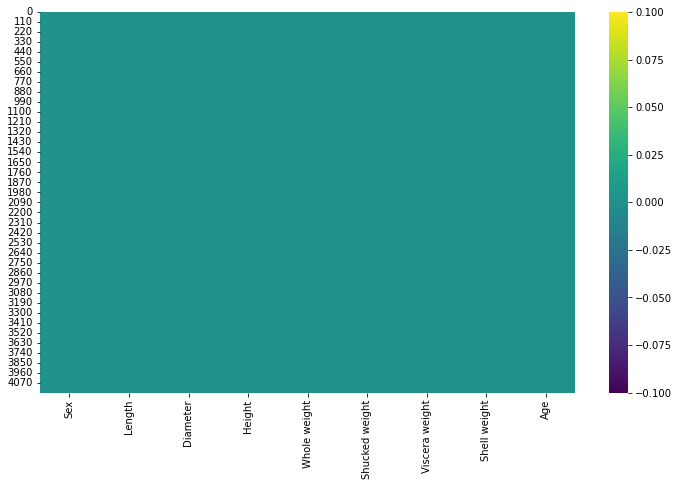

In [5]:
plt.rcParams['figure.figsize'] = (12, 7)
sns.heatmap(data.isnull(),cmap ='viridis') 

**The following also confirms that our data contains no missing values and that the data type of all the features variables is float64, whereas the data type of target variable (species) is object**

In [6]:
data.isnull().sum()

Sex               0
Length            0
Diameter          0
Height            0
Whole weight      0
Shucked weight    0
Viscera weight    0
Shell weight      0
Age               0
dtype: int64

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   object 
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole weight    4177 non-null   float64
 5   Shucked weight  4177 non-null   float64
 6   Viscera weight  4177 non-null   float64
 7   Shell weight    4177 non-null   float64
 8   Age             4177 non-null   float64
dtypes: float64(8), object(1)
memory usage: 293.8+ KB


**Below shows variation of abalone based on gender**

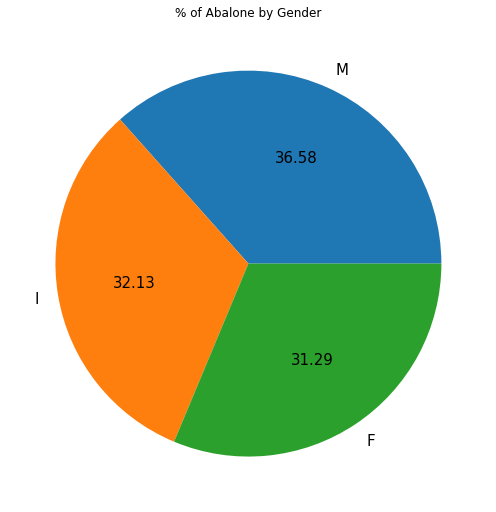

In [8]:
jk = data["Sex"].value_counts(normalize= True)
jk.plot(kind='pie', figsize= (7,10), title = "% of Abalone by Gender", ylabel = "", 
        autopct = "%.2f", fontsize = 15)

plt.tight_layout()
plt.show()

## Descriptive stats
 - Below shows that the height have minimum value of zero which doesn't make sense for a fish to have zero height. This might implies we have outliers in this dataset.
 
 - The  features seems to be having the same scale but their mean and standard deviation are far bit off  which implies we might not need to scale this features since they seems to be within the same scale.
 
 

In [9]:
data.describe()

,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Age
count,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000
mean,0.523992,0.407881,0.139516,0.828742,0.359367,0.180594,0.238831,11.433684
std,0.120093,0.099240,0.041827,0.490389,0.221963,0.109614,0.139203,3.224169
min,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,2.500000
25%,0.450000,0.350000,0.115000,0.441500,0.186000,0.093500,0.130000,9.500000
50%,0.545000,0.425000,0.140000,0.799500,0.336000,0.171000,0.234000,10.500000
75%,0.615000,0.480000,0.165000,1.153000,0.502000,0.253000,0.329000,12.500000
max,0.815000,0.650000,1.130000,2.825500,1.488000,0.760000,1.005000,30.500000


#### Filtering the data where height is zero

- below shows that the height of zero is for the infant abalone
- let's further investigate the height of non-zero infants

In [10]:
height_df = data.loc[(data['Height'] == 0)]
height_df

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Age
1257,I,0.430,0.34,0.0,0.428,0.2065,0.0860,0.1150,9.5
3996,I,0.315,0.23,0.0,0.134,0.0575,0.0285,0.3505,7.5


**Below also shows the following:**

- Abalones with the height of zero are older than some abalones with hegiht, 
- abalone with a hight of zero weigh more than abalone with a height of zero,
- with these analysis i conclude that there cannot be a living thing with a zero height, this could be a typing error which form some sort of outliers, hence the next step would be to look for outliers in our dataset 

In [11]:
Infant_df = data.loc[(data['Sex'] == "I")]
Infant_df

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Age
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,8.5
5,I,0.425,0.300,0.095,0.3515,0.1410,0.0775,0.120,9.5
16,I,0.355,0.280,0.085,0.2905,0.0950,0.0395,0.115,8.5
21,I,0.380,0.275,0.100,0.2255,0.0800,0.0490,0.085,11.5
42,I,0.240,0.175,0.045,0.0700,0.0315,0.0235,0.020,6.5
...,...,...,...,...,...,...,...,...,...
4158,I,0.480,0.355,0.110,0.4495,0.2010,0.0890,0.140,9.5
4163,I,0.390,0.310,0.085,0.3440,0.1810,0.0695,0.079,8.5
4164,I,0.390,0.290,0.100,0.2845,0.1255,0.0635,0.081,8.5
4165,I,0.405,0.300,0.085,0.3035,0.1500,0.0505,0.088,8.5


In [12]:
age30_df = data.loc[data['Age'] >= 30]
df_age30 = age30_df.groupby(['Sex'])['Age'].count()
df_age30

Sex
F    1
Name: Age, dtype: int64

### CHECKING FOR CORELATION AND  MULTICOLINEARITY 

- Correlation coefficients whose magnitude are between 0.9 and 1.0 indicate variables which can be considered perfectly highly correlated. 
- Correlation coefficients whose magnitude are between 0.7 and 0.9 indicate variables which can be considered highly correlated. 
- Correlation coefficients whose magnitude are between 0.5 and 0.7 indicate variables which can be considered moderately correlated. 
- Correlation coefficients whose magnitude are between 0.3 and 0.5 indicate variables which have a low correlation.

- Correlation coefficients whose magnitude are less than 0.3 have little if any (linear) correlation.

<AxesSubplot:>

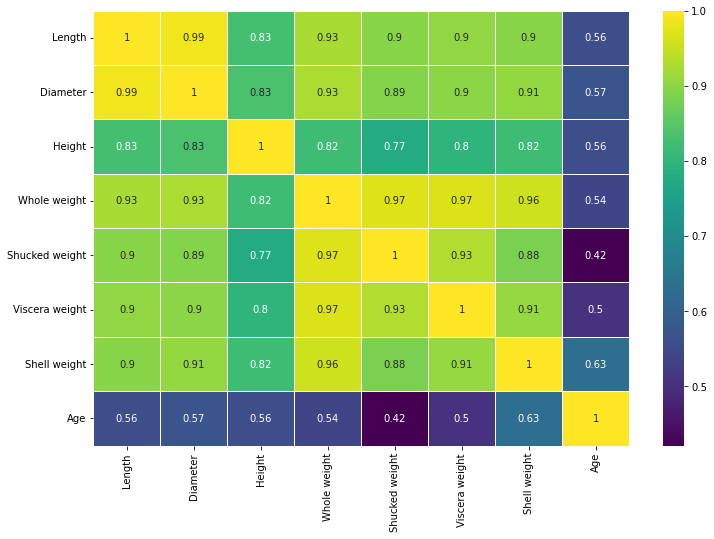

In [13]:
plt.rcParams['figure.figsize'] = (12, 8)
sns.heatmap(data.corr(), annot= True, linewidths = 0.5, cmap ='viridis')

### Target variable
* Correlation plot shows that all features are corelated to the target variable (age) which assumes linearity between our features and target variable age.Only shucked weight have low corelation.

* features are moderately corelated to each other which only mean we will need to solve for this in order teo use Linear regression model while meeting its assumptions. 


### Features
* feature are hightly corelated to each other and this only mean multicolinearity is present in our data which is not friendly to regression models.

* to use regression models we will need to solve for multicolinearity using one of techniques that can be ised to solve for multicolinearity such as pca, lasso regression, linearly combine the features etc

* Alternatevely, we can use based tree models because they are non-parametric, capable of handling complex relationships among variables and they're therefore immune to multicollinearity

# Testing for Homoscedasticity using white test

Homoscedasticity means that the error doesn’t doesn’t change across all the values of the independent variable.

**Hypothesis**
- H0: homoscedasticity
- H1: Heteroscedasticity
    
Having a p-value ≤ 0.05 would indicate that the null hypothesis is rejected, hence Heteroscedasticity.

In [14]:
#Importing Libraries
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_white
from statsmodels.compat import lzip
#data without categorical features
df = data.drop(["Sex"],axis =1)
#The variables
a=df[['Length', 'Diameter', 'Height', 'Whole weight', 'Shucked weight','Viscera weight', 'Shell weight']].values
a = sm.add_constant(a)
b = df['Age'].values
#Fit the model
model = sm.OLS(b,a).fit()

#The test
white_test = het_white(model.resid,  model.model.exog)
#Zipping the array with labels
names = ['Lagrange multiplier statistic', 'p-value','f-value', 'f p-value']
lzip(names,white_test)

[('Lagrange multiplier statistic', 742.509179983759),
 ('p-value', 1.789787382669535e-133),
 ('f-value', 25.57859312189487),
 ('f p-value', 2.84768355761388e-148)]

**Our p_value < 0.05, hence we reject H0, which implies that heteroscedastic is present in our data**
This only mean we can't fit linear regression model to this data set because our model will be too simple for our data and that will results in underfitting.


**What to do if there is Heteroscedasticity?**

- Outlier removal
- Log transformation of x variables
- Polynomial regresion

## checking for outliers on our data

Box plot and density plot are used to detect outliers

<AxesSubplot:xlabel='variable', ylabel='value'>

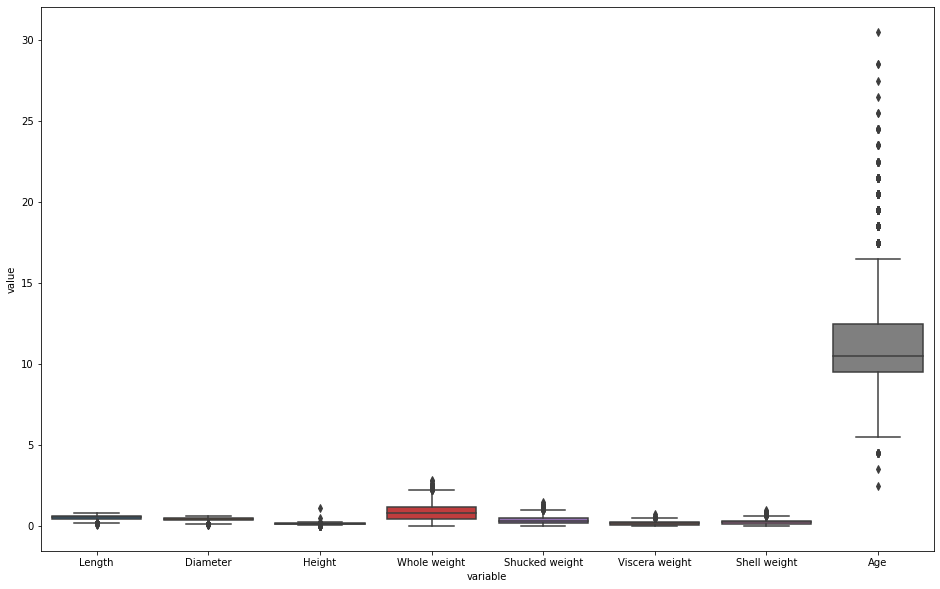

In [15]:
#dropping categorical features 
df_outliers = data.drop('Sex', axis =1)
plt.figure(figsize = (16,10))
df_melted = pd.melt(df_outliers)
sns.boxplot(x='variable', y='value', data=df_melted)

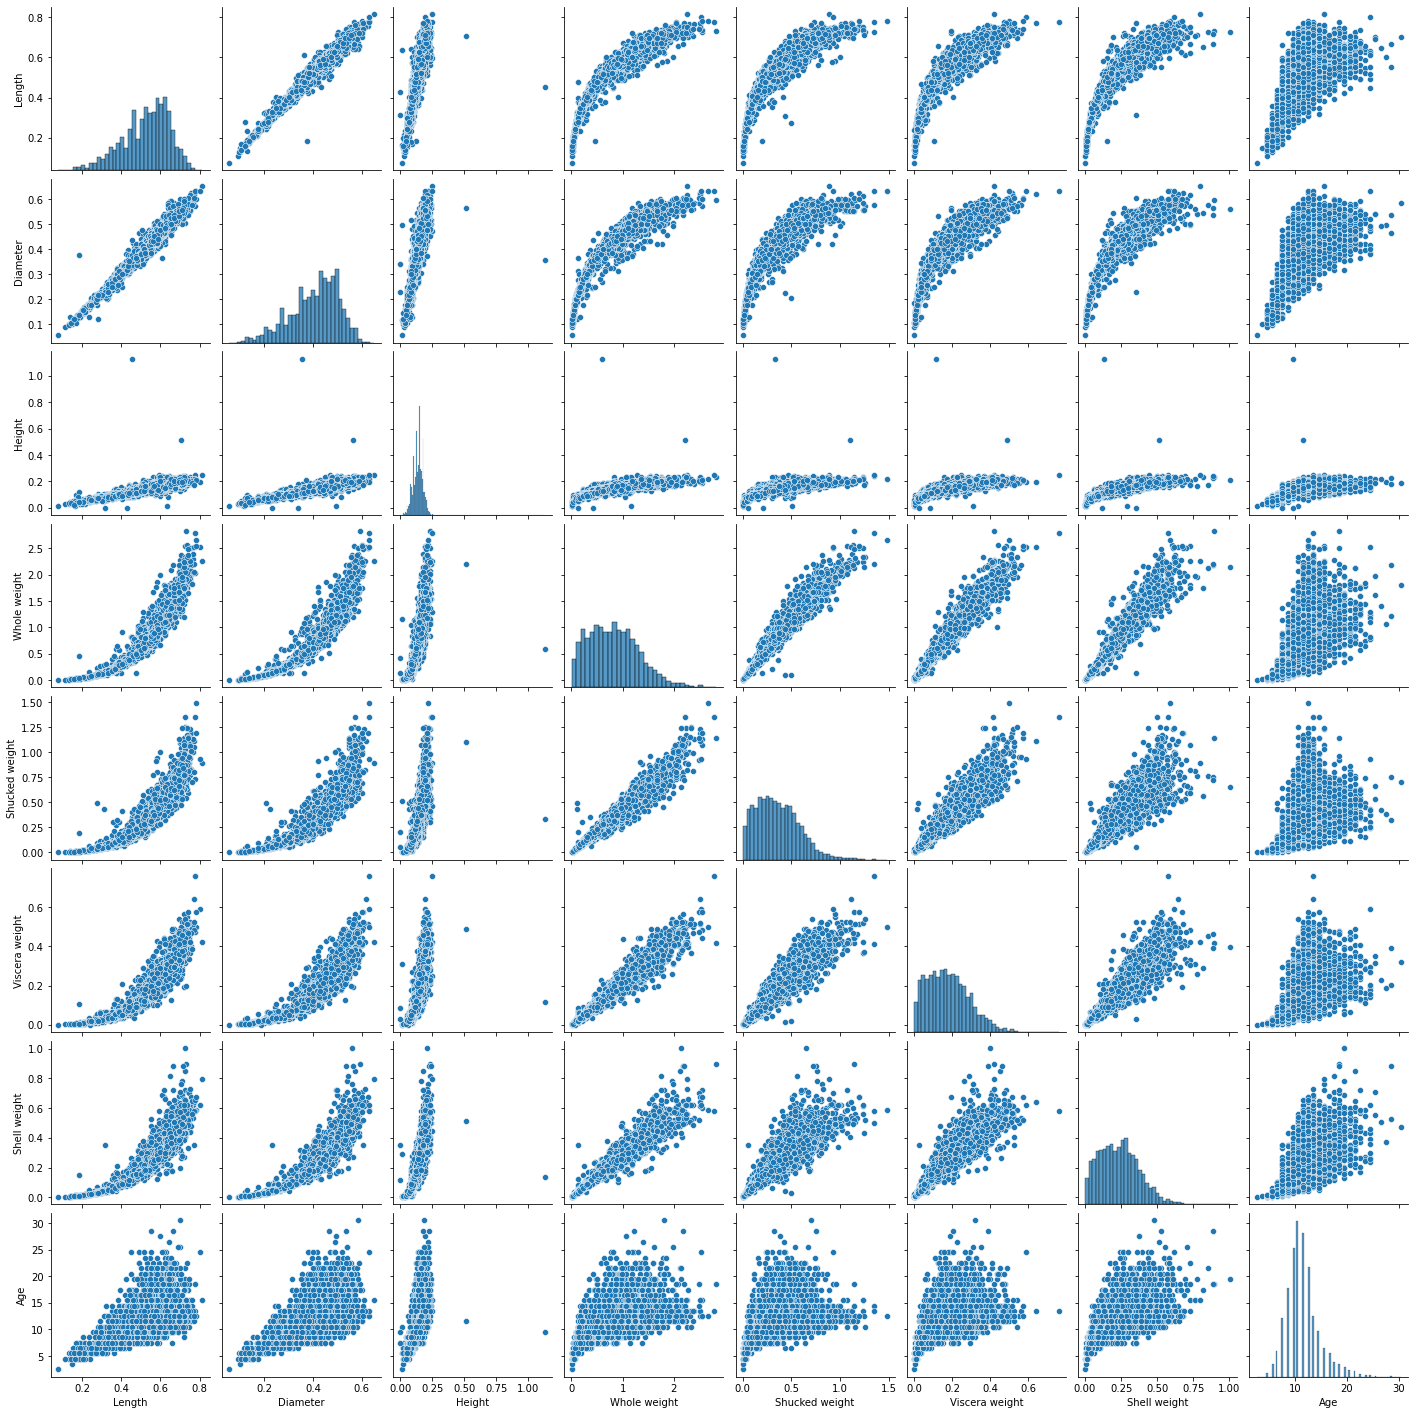

In [16]:
sns.pairplot(data)

In [17]:
data.columns

Index(['Sex', 'Length', 'Diameter', 'Height', 'Whole weight', 'Shucked weight',
       'Viscera weight', 'Shell weight', 'Age'],
      dtype='object')

## Remove Outliers

In [18]:
def out_iqr(df , column):
    global lower,upper
    q25, q75 = np.quantile(df[column], 0.25), np.quantile(df[column], 0.75)
    # calculate the IQR
    iqr = q75 - q25
    # calculate the outlier cutoff
    cut_off = iqr * 1.5
    # calculate the lower and upper bound value
    lower, upper = q25 - cut_off, q75 + cut_off
    print('The IQR is',iqr)
    print('The lower bound value is', lower)
    print('The upper bound value is', upper)
    # Calculate the number of records below and above lower and above bound value respectively
    df1 = df[df[column] > upper]
    df2 = df[df[column] < lower]
    return print('Total number of outliers are', df1.shape[0]+ df2.shape[0])

def remove_outliers(df,column,lower_bound, upper_bound):
    # dropping outliers below lower bound
    data.drop(df[df[column]  < lower_bound].index, inplace=True)
    # dropping outliers above upper bound
    data.drop(df[df[column] >  upper_bound].index, inplace=True)
    return df

In [19]:
data.columns

Index(['Sex', 'Length', 'Diameter', 'Height', 'Whole weight', 'Shucked weight',
       'Viscera weight', 'Shell weight', 'Age'],
      dtype='object')

In [20]:
out_iqr(data,'Height')

The IQR is 0.05
The lower bound value is 0.039999999999999994
The upper bound value is 0.24000000000000002
Total number of outliers are 29


In [21]:
out_iqr(data,'Whole weight')

The IQR is 0.7115
The lower bound value is -0.62575
The upper bound value is 2.22025
Total number of outliers are 30


In [22]:
out_iqr(data,'Shucked weight')

The IQR is 0.316
The lower bound value is -0.288
The upper bound value is 0.976
Total number of outliers are 48


In [23]:
out_iqr(data,'Length')

The IQR is 0.16499999999999998
The lower bound value is 0.20250000000000004
The upper bound value is 0.8624999999999999
Total number of outliers are 49


In [24]:
out_iqr(data,'Diameter')

The IQR is 0.13
The lower bound value is 0.15499999999999997
The upper bound value is 0.675
Total number of outliers are 59


In [25]:
out_iqr(data,'Viscera weight')

The IQR is 0.1595
The lower bound value is -0.14575000000000002
The upper bound value is 0.49225
Total number of outliers are 26


In [26]:
out_iqr(data,'Age')

The IQR is 3.0
The lower bound value is 5.0
The upper bound value is 17.0
Total number of outliers are 278


Removing so many outliers may results in loosing important information from the data. The max age on target is 30.5 which forms part of the outliers and research says the abalone can live up to the age of 13 years. Hence we will only remove outliers on Age which is our target variable and outliers on height which seems to be way too off

In [27]:
# removing outliers on age
data = remove_outliers(data,"Age",5, 17)

In [28]:
# # removing outliers on height
data = remove_outliers(data,"Height",0.039999999999999994,0.24000000000000002)

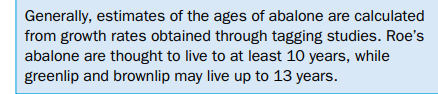

**ref**: https://www.fish.wa.gov.au/Documents/recreational_fishing/fact_sheets/fact_sheet_abalone.pdf

In [29]:
#the min value for height is now 0.01  
data.describe()

,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Age
count,3878.000000,3878.000000,3878.000000,3878.000000,3878.000000,3878.000000,3878.000000,3878.000000
mean,0.521625,0.405504,0.137715,0.808629,0.355766,0.177240,0.229777,10.924703
std,0.117313,0.096769,0.036799,0.478945,0.221646,0.108054,0.130467,2.369934
min,0.135000,0.105000,0.040000,0.017500,0.005000,0.000500,0.005000,5.500000
25%,0.446250,0.345000,0.110000,0.429625,0.180500,0.090000,0.125000,9.500000
50%,0.535000,0.420000,0.140000,0.771500,0.328500,0.165750,0.221750,10.500000
75%,0.610000,0.480000,0.165000,1.132500,0.498500,0.247000,0.316375,12.500000
max,0.780000,0.630000,0.240000,2.657000,1.488000,0.641500,0.760000,16.500000


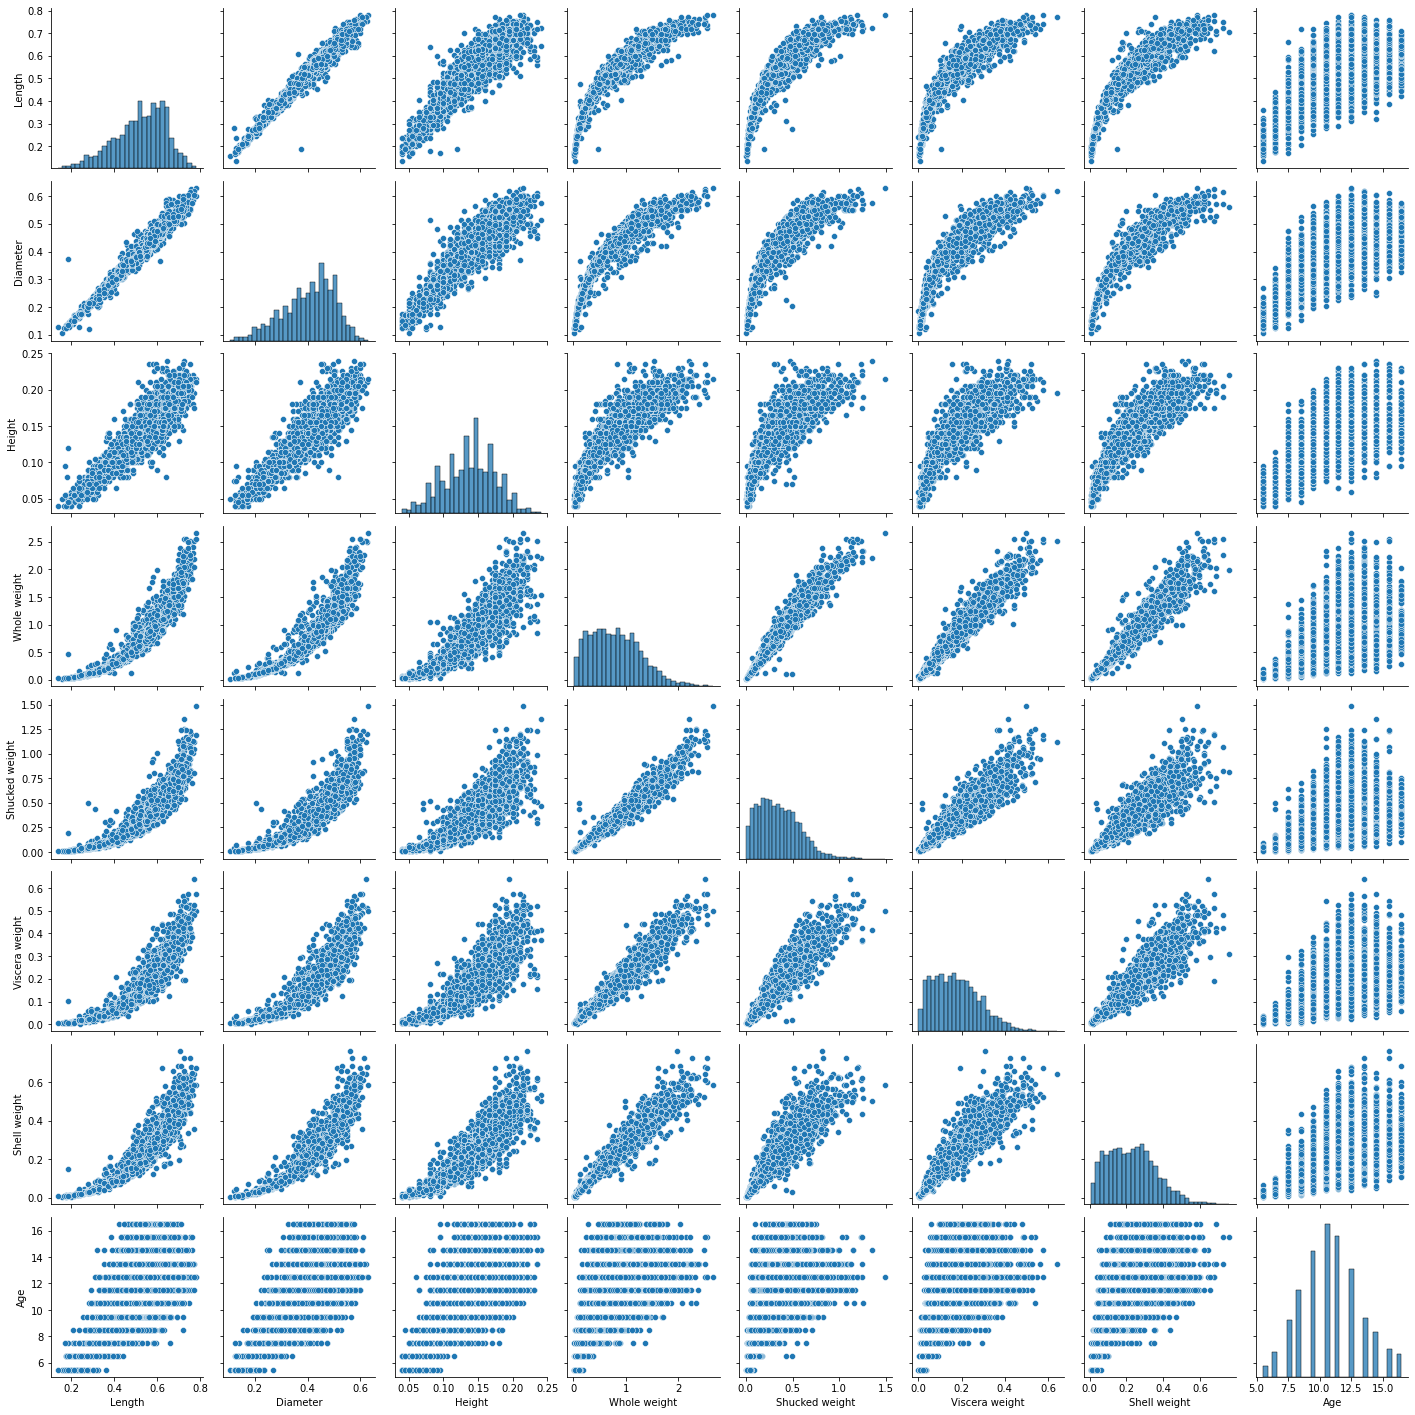

In [30]:
sns.pairplot(data)

### AFTER REMOVING OUTLIERS

<AxesSubplot:>

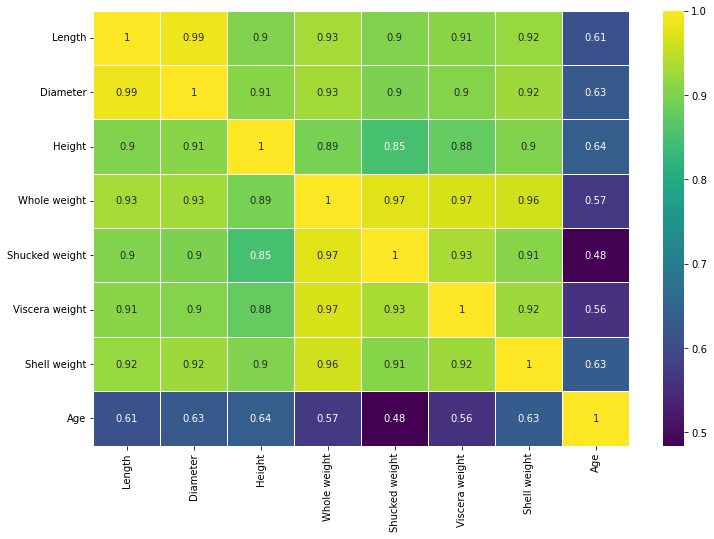

In [31]:
plt.rcParams['figure.figsize'] = (12, 8)
sns.heatmap(data.corr(), annot= True, linewidths = 0.5, cmap ='viridis')

### First converting categorical data into dummy

In [32]:
data = pd.get_dummies(data)
data.head()

,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Age,Sex_F,Sex_I,Sex_M
0,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,16.5,0,0,1
1,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,8.5,0,0,1
2,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,10.5,1,0,0
3,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,11.5,0,0,1
4,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,8.5,0,1,0


## Feature selection

In [33]:
import statsmodels.api as sm

#### Backward Elimination

**The performance metric used here to evaluate feature performance is pvalue. If the pvalue is above 0.05 then we remove the feature, else we keep it.**

In [34]:
data.columns

Index(['Length', 'Diameter', 'Height', 'Whole weight', 'Shucked weight',
       'Viscera weight', 'Shell weight', 'Age', 'Sex_F', 'Sex_I', 'Sex_M'],
      dtype='object')

In [35]:
#The variables
X=data[['Length', 'Diameter', 'Height', 'Whole weight', 'Shucked weight',
        'Viscera weight', 'Shell weight','Sex_F', 'Sex_I', 'Sex_M']]
y = data[['Age']]

cols = list(X.columns)
pmax = 1
while (len(cols)>0):
    p= []
    X_1 = X[cols]
    X_1 = sm.add_constant(X_1)
    model = sm.OLS(y,X_1).fit()
    p = pd.Series(model.pvalues.values[1:],index = cols)      
    pmax = max(p)
    feature_with_p_max = p.idxmax()
    if(pmax>0.05):
        cols.remove(feature_with_p_max)
    else:
        break
selected_features_BE = cols
print(selected_features_BE)

['Diameter', 'Height', 'Whole weight', 'Shucked weight', 'Viscera weight', 'Shell weight', 'Sex_F', 'Sex_I', 'Sex_M']


In [36]:
model.pvalues

const             2.280168e-109
Diameter           1.250443e-28
Height             6.242757e-18
Whole weight       8.421594e-10
Shucked weight     9.181495e-59
Viscera weight     9.912887e-04
Shell weight       4.742616e-09
Sex_F              1.943207e-81
Sex_I              3.351653e-32
Sex_M             2.185422e-104
dtype: float64

**pvalues for all features are less than 0.05, hence no feature is eliminated by this method**

**length excluded by backward elimination**

### Lasso regression

 **If the feature is irrelevant, lasso penalizes it’s coefficient and make it 0. Hence the features with coefficient = 0 are removed and the rest are taken.**

In [37]:
from sklearn.linear_model import LassoCV
reg = LassoCV()
reg.fit(X, y)
print("Best alpha using built-in LassoCV: %f" % reg.alpha_)
print("Best score using built-in LassoCV: %f" %reg.score(X,y))
coef = pd.Series(reg.coef_, index = X.columns)

Best alpha using built-in LassoCV: 0.000648
Best score using built-in LassoCV: 0.521029


In [38]:
print("Lasso picked " + str(sum(coef != 0)) + " variables and eliminated the other " +  str(sum(coef == 0)) + " variables")

Lasso picked 9 variables and eliminated the other 1 variables


Text(0.5, 1.0, 'Feature importance using Lasso Model')

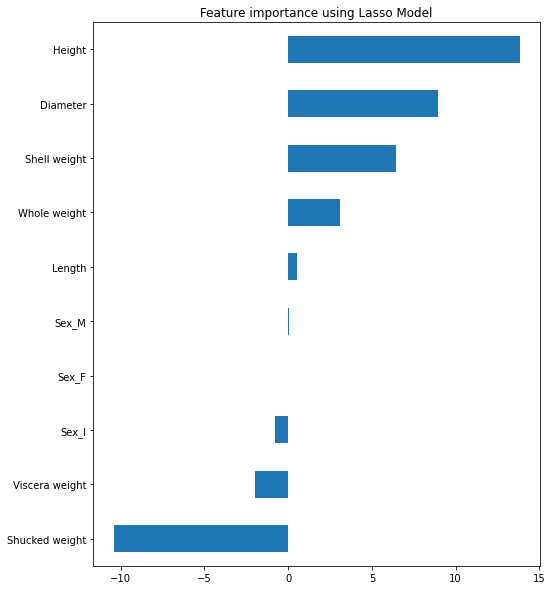

In [39]:
imp_coef = coef.sort_values()
import matplotlib
matplotlib.rcParams['figure.figsize'] = (8.0, 10.0)
imp_coef.plot(kind = "barh")
plt.title("Feature importance using Lasso Model")

In [40]:
# coefficents for each features
coef

Length             0.529045
Diameter           8.947528
Height            13.812618
Whole weight       3.073397
Shucked weight   -10.410115
Viscera weight    -1.963215
Shell weight       6.409003
Sex_F             -0.000000
Sex_I             -0.774844
Sex_M              0.072530
dtype: float64

## Data Spliting

### X and y  arrays

In [41]:
data.columns

Index(['Length', 'Diameter', 'Height', 'Whole weight', 'Shucked weight',
       'Viscera weight', 'Shell weight', 'Age', 'Sex_F', 'Sex_I', 'Sex_M'],
      dtype='object')

In [42]:
X = data.drop(['Age'],axis=1)
y = data[["Age"]]

## Solve multicolinearity with PCA

PCA is a linear dimensionality reduction technique (algorithm) that transforms a set of correlated variables (p) into a smaller k (k<p) number of uncorrelated variables called principal components while retaining as much of the variation in the original dataset as possible.

**Scaling data with standadisation**

In [43]:
from sklearn.preprocessing import StandardScaler
Scaling=StandardScaler()
X_scaled = StandardScaler().fit_transform(X)

In [44]:
from sklearn.decomposition import PCA
pca = PCA(n_components=None)
pca.fit(X_scaled)

PCA()

**Get the eigenvalues**

In [45]:
print("Eigenvalues:")
print(pca.explained_variance_)
print()

Eigenvalues:
[7.09099583e+00 1.50800309e+00 9.23027797e-01 1.96963217e-01
 1.24758683e-01 7.77377623e-02 6.18741562e-02 1.29909732e-02
 6.22780633e-03 5.07240273e-32]



**Get explained variances**

In [46]:
print("Variances (Percentage):")
print(pca.explained_variance_ratio_ * 100)
print()

Variances (Percentage):
[7.08916732e+01 1.50761423e+01 9.22789780e+00 1.96912427e+00
 1.24726512e+00 7.77177165e-01 6.18582010e-01 1.29876233e-01
 6.22620040e-02 5.07109474e-31]



In [47]:
np.cumsum(pca.explained_variance_ratio_)

array([0.70891673, 0.85967815, 0.95195713, 0.97164837, 0.98412103,
       0.9918928 , 0.99807862, 0.99937738, 1.        , 1.        ])

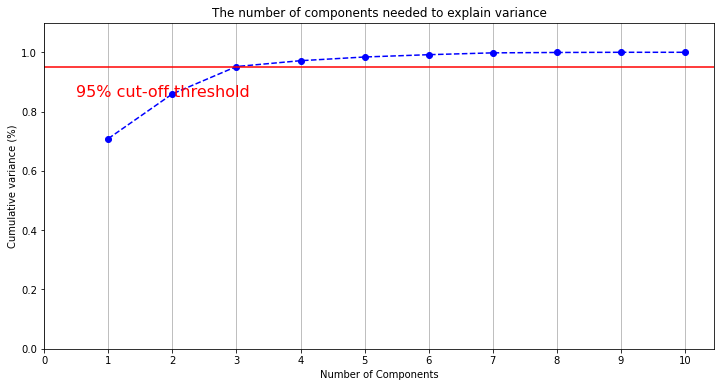

In [48]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (12,6)

fig, ax = plt.subplots()
xi = np.arange(1, 11, step=1)
yi = np.cumsum(pca.explained_variance_ratio_)

plt.ylim(0.0,1.1)
plt.plot(xi, yi, marker='o', linestyle='--', color='b')

plt.xlabel('Number of Components')
plt.xticks(np.arange(0, 11, step=1)) #change from 0-based array index to 1-based human-readable label
plt.ylabel('Cumulative variance (%)')
plt.title('The number of components needed to explain variance')

plt.axhline(y=0.95, color='r', linestyle='-')
plt.text(0.5, 0.85, '95% cut-off threshold', color = 'red', fontsize=16)

ax.grid(axis='x')
plt.show()

we can also use this simple method to see no of components

In [49]:
from sklearn.decomposition import PCA
pca = PCA(n_components=0.95)
pca.fit(X_scaled)
pca.n_components_

3

**To get 95% of variance explained I need 3 principal components.**

### Scale data with standadisation and fit data to PCA

In [50]:
# Do feature scaling
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_scaled = sc.fit_transform(X)

# Apply PCA
from sklearn.decomposition import PCA
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

# Get the transformed dataset
X_pca = pd.DataFrame(X_pca)
print(X_pca.head())
print("\nSize: ")
print(X_pca.shape)

          0         1         2
0 -1.441790  1.533731 -1.150852
1 -3.006154  1.567667 -1.663528
2 -0.084005 -1.490835 -1.159326
3 -1.157627  1.518693 -1.094698
4 -4.065584 -0.183649  0.517230

Size: 
(3878, 3)


<AxesSubplot:>

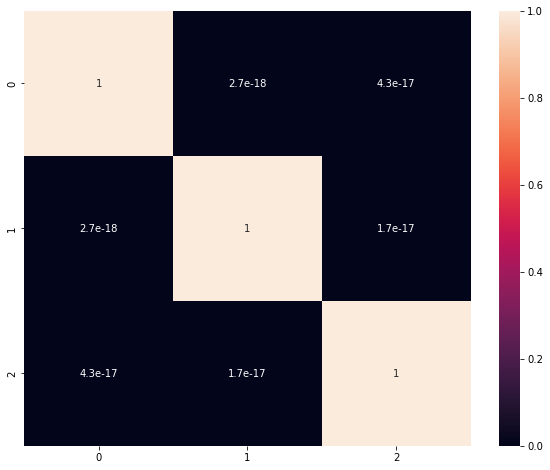

In [51]:
fig = plt.figure(figsize=(10, 8))
sns.heatmap(X_pca.corr(), 
            annot=True)

In [52]:
y.shape

(3878, 1)

In [53]:
#data without categorical features
X_with_constant = sm.add_constant(X_pca)
y_white = y.to_numpy()
#Fit the model
model = sm.OLS(y_white,X_with_constant).fit()

#The test
white_test = het_white(model.resid,  model.model.exog)
#Zipping the array with labels
names = ['Lagrange multiplier statistic', 'p-value','f-value', 'f p-value']
lzip(names,white_test)

[('Lagrange multiplier statistic', 116.8699259445389),
 ('p-value', 5.83535695771828e-21),
 ('f-value', 13.354522729212249),
 ('f p-value', 2.75006147150116e-21)]

### The multicolinearity is solved in our data but the heteroscedasticity is still present hence, we still cant use the linear regression to fit this data set. let's either use tree-base models or polynomial model

## Data Modelling

Now we need to implement different regression models and see which one gives the best results based on the accuracy level.

In [54]:
#Acurracy library
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error

## 1. Polynomial regression

## Train Test Split

Now let's split the data into a training set and a testing set. We will train our model on the training set and then use the test set to evaluate the model.

In [55]:
from sklearn.model_selection import train_test_split
X_train_poly, X_test_poly, y_train_poly, y_test_poly = train_test_split(X_pca, y, test_size = 0.2, random_state = 0)
X_train_poly.shape, X_test_poly.shape, y_train_poly.shape, y_test_poly.shape

((3102, 3), (776, 3), (3102, 1), (776, 1))

In [56]:
from sklearn import linear_model
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

#number of degree
degree=3


#Initializing KNN model
polyreg_model=make_pipeline(PolynomialFeatures(degree),LinearRegression())
#Train the model using Training Dataset
polyreg_model.fit(X_train_poly, y_train_poly)

# Prediction using test data
y_pred_poly = polyreg_model.predict(X_test_poly)

# Calculate Model accuracy by comparing y_test and y_pred
polyreg_model_accuracy = r2_score(y_test_poly, y_pred_poly)
poly_reg_error =mean_absolute_error(y_true= y_test_poly,y_pred=y_pred_poly)
print('Accuracy of linear Regression model : ', round(polyreg_model_accuracy,2))
print('Mae score is:', round(poly_reg_error,2))

Accuracy of linear Regression model :  0.53
Mae score is: 1.25


## 2. Random Forest Regression

Random forest regressor is the tree based model and that makes it immune to multicolinearity which is then best for our data sicne it suffers from multicolinearity 

### Train Test Split

Now let's split the data into a training set and a testing set. We will train our model on the training set and then use the test set to evaluate the model.

In [57]:
from sklearn.model_selection import train_test_split
X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(X, y, test_size = 0.2, random_state = 0)
X_train_rf.shape, X_test_rf.shape, y_train_rf.shape, y_test_poly.shape

((3102, 10), (776, 10), (3102, 1), (776, 1))

**Randomised grid search hyperparameter tuning**

references:
- https://analyticsindiamag.com/guide-to-hyperparameters-tuning-using-gridsearchcv-and-randomizedsearchcv/
- https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html#sklearn.ensemble.RandomForestRegressor


### Create a random hyperparameter grid.

In [58]:
from sklearn.model_selection import RandomizedSearchCV

# Number of trees in random forest
n_estimators = [int(x) for x in np.linspace(start = 100, stop = 1000, num = 20)]
# Number of features to consider at every split
max_features = ['auto', 'sqrt']
# Maximum number of levels in tree
max_depth = [int(x) for x in np.linspace(10, 110, num = 11)]
max_depth.append(None)
# Minimum number of samples required to split a node
min_samples_split = [2, 5, 10]
# Minimum number of samples required at each leaf node
min_samples_leaf = [1, 2, 4]
# Method of selecting samples for training each tree
bootstrap = [True, False]
# Create the random grid
random_grid = {'n_estimators': n_estimators,
               'max_features': max_features,
               'max_depth': max_depth,
               'min_samples_split': min_samples_split,
               'min_samples_leaf': min_samples_leaf,
               'bootstrap': bootstrap}
print(random_grid)

{'n_estimators': [100, 147, 194, 242, 289, 336, 384, 431, 478, 526, 573, 621, 668, 715, 763, 810, 857, 905, 952, 1000], 'max_features': ['auto', 'sqrt'], 'max_depth': [10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, None], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4], 'bootstrap': [True, False]}


### Implement random search training 

Random search of parameters, using 3 fold cross validation

In [59]:
# Library
from sklearn.ensemble import RandomForestRegressor


# Use the random grid to search for best hyperparameters

#Initializing base line modelmto tune
rf_model= RandomForestRegressor()

# Random search of parameters, using 3 fold cross validation, 
# search across 100 different combinations, and use all available cores
regressor_random = RandomizedSearchCV(estimator = rf_model,
                                      param_distributions = random_grid,
                                      n_iter = 20,
                                      cv = 3,
                                      verbose=2,
                                      random_state=42,)

#Training the model using the Training Dataset
regressor_random.fit(X_train_rf, y_train_rf)

#Model Prediction using test data
y_pred_rf = regressor_random.predict(X_test_rf)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
[CV] END bootstrap=False, max_depth=90, max_features=auto, min_samples_leaf=2, min_samples_split=2, n_estimators=573; total time=   4.3s
[CV] END bootstrap=False, max_depth=90, max_features=auto, min_samples_leaf=2, min_samples_split=2, n_estimators=573; total time=   4.4s
[CV] END bootstrap=False, max_depth=90, max_features=auto, min_samples_leaf=2, min_samples_split=2, n_estimators=573; total time=   4.4s
[CV] END bootstrap=True, max_depth=30, max_features=auto, min_samples_leaf=4, min_samples_split=5, n_estimators=100; total time=   0.4s
[CV] END bootstrap=True, max_depth=30, max_features=auto, min_samples_leaf=4, min_samples_split=5, n_estimators=100; total time=   0.3s
[CV] END bootstrap=True, max_depth=30, max_features=auto, min_samples_leaf=4, min_samples_split=5, n_estimators=100; total time=   0.3s
[CV] END bootstrap=False, max_depth=30, max_features=sqrt, min_samples_leaf=4, min_samples_split=10, n_estimators=573; t

**Getting best parameters**

In [60]:
# This will give us best parameter for our models
regressor_random.best_params_

{'n_estimators': 384,
 'min_samples_split': 10,
 'min_samples_leaf': 2,
 'max_features': 'auto',
 'max_depth': 20,
 'bootstrap': True}

In [61]:
base_model = RandomForestRegressor(n_estimators = 336, min_samples_split = 5, min_samples_leaf = 4, max_features ="auto",
                                   max_depth =100, bootstrap = True)
base_model.fit(X_train_rf, y_train_rf)
rf_model_accuracy = r2_score(y_test_rf, y_pred_rf)
rf_error= mean_absolute_error(y_true= y_test_rf,y_pred=y_pred_rf)
print('Rf regressor_accuracy : ', rf_model_accuracy)
print('MAE is:', rf_error)

Rf regressor_accuracy :  0.570841812252407
MAE is: 1.1967253615133349


### Model selection

The table a below shows the best performing algorithms in descending order based on highest accuracy of the last prediction of each algorithm**

In [64]:
models = pd.DataFrame({
    'Model': ['Random forest regressor', 'polynomial regression'],
    'Score': [round(rf_model_accuracy*100,2), round(polyreg_model_accuracy*100,2)],
    'MAE': [round(rf_error,2), round(poly_reg_error,2)]})

models.sort_values(by='Score', ascending=False)

,Model,Score,MAE
0,Random forest regressor,57.08,1.20
1,polynomial regression,53.32,1.25
